# 分類データセットの確認

``activity_demo_book.ipynb``, ``activity_percent_demo_book.ipynb``で作成したデータセットを連結し、重複除去する。

重複除去する際は``chembl_34_activity.csv``のデータのレコードを基準に、ラベルはVotingで決める。

table
| Version | Comment | Records |
|----------|----------|----------|
| v1 | initial code |  |
| v2 | percent -10 to 110 | |
| v4 | molecular weight < 2000 |  |

In [2]:
import pandas as pd

In [3]:
df_act = pd.read_csv("chembl_34_activity.csv", index_col=0)
df_act_pct = pd.read_csv("chembl_34_activity_percent_v2.csv")

/tmp/ipykernel_765263/3177331144.py:1: DtypeWarning: Columns (21) have mixed types. Specify dtype option on import or set low_memory=False.
  df_act = pd.read_csv("chembl_34_activity.csv", index_col=0)


In [4]:
df = pd.concat([df_act, df_act_pct], axis=0).reset_index(drop=True)

In [5]:
df["compound_id"] = df["smiles"].factorize()[0]
df["protein_id"] = df["target_sequence"].factorize()[0]
df["cp_id"] = df["compound_id"].astype(str) + "_" + df["protein_id"].astype(str)

In [6]:
df["cp_id"].value_counts()

cp_id
516902_1278    531
516902_1859    466
516902_1861    393
85355_137      349
85355_140      302
              ... 
451505_952       1
451504_952       1
451503_952       1
451502_952       1
451511_952       1
Name: count, Length: 1554237, dtype: int64

In [7]:
df_not_duplicated = df.drop_duplicates(subset=["cp_id"], keep=False)
df_duplicated = df[df.duplicated(subset=["cp_id"], keep=False)]

In [8]:
len(df_not_duplicated), len(df_duplicated)

(1239346, 833494)

In [9]:
import numpy as np
def vote(x):
    if np.isnan(x):
        return None
    if x >= 0.5:
        return 1
    else:
        return 0

In [10]:
df_duplicated_keep_first = df_duplicated.drop_duplicates(subset=["cp_id"], keep="first")

df_voted = df_duplicated.groupby("cp_id").mean(numeric_only=True)[["t_100n", "t_1u", "t_10u"]]

df_voted["t_100n"] = df_voted["t_100n"].apply(vote)
df_voted["t_1u"] = df_voted["t_1u"].apply(vote)
df_voted["t_10u"] = df_voted["t_10u"].apply(vote)

df_duplicated_keep_first = df_duplicated_keep_first.set_index("cp_id")
df_duplicated_keep_first.loc[df_voted.index, ["t_100n", "t_1u", "t_10u"]] = df_voted

In [11]:
df_duplicated_keep_first["t_1u"].value_counts()

t_1u
1.0    198556
0.0     98373
Name: count, dtype: int64

In [12]:
df_all = pd.concat([df_not_duplicated, df_duplicated_keep_first.reset_index()], axis=0).reset_index(drop=True)
df_all

,activity_id,assay_id,target_chembl_id,target_name,target_organism,target_accession,target_sequence,compound_chembl_id,smiles,standard_type,...,family,subfamily,description,assay_conc_full,assay_conc,assay_conc_units,assay_conc_uM,compound_id,protein_id,cp_id
0,22482022,2033487,CHEMBL322,Serotonin 2a (5-HT2a) receptor,Rattus norvegicus,P14842,MEILCEDNISLSSIPNSLMQLGDGPRLYHNDFNSRDANTSEASNWT...,CHEMBL190461,C=C(C)[C@@H]1CCC(C)=C[C@H]1c1c(O)cc(CCCCC)cc1O,EC50,...,G-protein coupled receptor 1 family,NaN,NaN,NaN,NaN,NaN,NaN,31,0,31_0
1,73552,2708,CHEMBL322,Serotonin 2a (5-HT2a) receptor,Rattus norvegicus,P14842,MEILCEDNISLSSIPNSLMQLGDGPRLYHNDFNSRDANTSEASNWT...,CHEMBL300209,CN(C)CCc1c[nH]c2ccc(Cc3nnn[nH]3)cc12,IC50,...,G-protein coupled receptor 1 family,NaN,NaN,NaN,NaN,NaN,NaN,32,0,32_0
2,75762,2708,CHEMBL322,Serotonin 2a (5-HT2a) receptor,Rattus norvegicus,P14842,MEILCEDNISLSSIPNSLMQLGDGPRLYHNDFNSRDANTSEASNWT...,CHEMBL54265,CN(C)CCc1c[nH]c2ccc(-n3cncn3)cc12,IC50,...,G-protein coupled receptor 1 family,NaN,NaN,NaN,NaN,NaN,NaN,33,0,33_0
3,75770,2708,CHEMBL322,Serotonin 2a (5-HT2a) receptor,Rattus norvegicus,P14842,MEILCEDNISLSSIPNSLMQLGDGPRLYHNDFNSRDANTSEASNWT...,CHEMBL53764,Cc1nccn1-c1ccc2[nH]cc(CCN(C)C)c2c1,IC50,...,G-protein coupled receptor 1 family,NaN,NaN,NaN,NaN,NaN,NaN,34,0,34_0
4,77929,2708,CHEMBL322,Serotonin 2a (5-HT2a) receptor,Rattus norvegicus,P14842,MEILCEDNISLSSIPNSLMQLGDGPRLYHNDFNSRDANTSEASNWT...,CHEMBL299213,CCn1nnc(Cc2ccc3[nH]cc(CCN(C)C)c3c2)n1,IC50,...,G-protein coupled receptor 1 family,NaN,NaN,NaN,NaN,NaN,NaN,35,0,35_0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1554232,24979599,2265902,CHEMBL6182,"NADP-dependent malic enzyme, mitochondrial",Homo sapiens,Q16798,MGAALGTGTRLAPWPGRACGALPRWTPTAPAQGCHSKPGPARPVPL...,CHEMBL5273212,COc1ccc(N2CCN(C(=O)CCc3ccccc3)CC2)nc1,Inhibition,...,Malic enzymes family,NaN,Inhibition of His-tagged human recombinant ME3...,1 uM,1.0,uM,1.0,764677,5177,764677_5177
1554233,24979600,2265902,CHEMBL6182,"NADP-dependent malic enzyme, mitochondrial",Homo sapiens,Q16798,MGAALGTGTRLAPWPGRACGALPRWTPTAPAQGCHSKPGPARPVPL...,CHEMBL5277883,O=C(CCc1ccccc1)N1CCN(c2ccc(F)cn2)CC1,Inhibition,...,Malic enzymes family,NaN,Inhibition of His-tagged human recombinant ME3...,1 uM,1.0,uM,1.0,764678,5177,764678_5177
1554234,24979601,2265902,CHEMBL6182,"NADP-dependent malic enzyme, mitochondrial",Homo sapiens,Q16798,MGAALGTGTRLAPWPGRACGALPRWTPTAPAQGCHSKPGPARPVPL...,CHEMBL5274411,O=C(Cc1ccccc1)N1CCC(c2ccc(O)cc2)CC1,Inhibition,...,Malic enzymes family,NaN,Inhibition of His-tagged human recombinant ME3...,1 uM,1.0,uM,1.0,764679,5177,764679_5177
1554235,25009472,2276097,CHEMBL5169136,RNA-binding protein FXR2,Homo sapiens,P51116,MGGLASGGDVEPGLPVEVRGSNGAFYKGFVKDVHEDSVTIFFENNW...,CHEMBL5274116,C[C@H]1CC(OCc2c(-c3c(Cl)cccc3Cl)noc2C2CC2)C[C@...,Activity,...,FMR1 family,NaN,Agonist activity at FXR2 in human HepG2 cells ...,0.3 uM,0.3,uM,0.3,764697,1149,764697_1149


In [13]:
df_all["t_1u"].value_counts()

t_1u
1.0    794558
0.0    607815
Name: count, dtype: int64

In [14]:
df_all.columns

Index(['activity_id', 'assay_id', 'target_chembl_id', 'target_name',
       'target_organism', 'target_accession', 'target_sequence',
       'compound_chembl_id', 'smiles', 'standard_type', 'relation',
       'standard_value', 'standard_units', 'pchembl_value',
       'protein_class_desc', 't_10u', 't_1u', 't_100n', 'Protein families',
       '3D', 'superfamily', 'family', 'subfamily', 'description',
       'assay_conc_full', 'assay_conc', 'assay_conc_units', 'assay_conc_uM',
       'compound_id', 'protein_id', 'cp_id'],
      dtype='object')

In [15]:
df_all_only_label = df_all.drop(columns=['standard_type', 'relation', 'standard_value',
                                         'standard_units', 'pchembl_value', 'assay_conc_full', 'assay_conc', 'assay_conc_units', 'assay_conc_uM'],
                                axis=1)

df_all_only_label

,activity_id,assay_id,target_chembl_id,target_name,target_organism,target_accession,target_sequence,compound_chembl_id,smiles,protein_class_desc,...,t_100n,Protein families,3D,superfamily,family,subfamily,description,compound_id,protein_id,cp_id
0,22482022,2033487,CHEMBL322,Serotonin 2a (5-HT2a) receptor,Rattus norvegicus,P14842,MEILCEDNISLSSIPNSLMQLGDGPRLYHNDFNSRDANTSEASNWT...,CHEMBL190461,C=C(C)[C@@H]1CCC(C)=C[C@H]1c1c(O)cc(CCCCC)cc1O,membrane receptor 7tm1 smallmol monoamine r...,...,0.0,G-protein coupled receptor 1 family,X-ray crystallography (1),NaN,G-protein coupled receptor 1 family,NaN,NaN,31,0,31_0
1,73552,2708,CHEMBL322,Serotonin 2a (5-HT2a) receptor,Rattus norvegicus,P14842,MEILCEDNISLSSIPNSLMQLGDGPRLYHNDFNSRDANTSEASNWT...,CHEMBL300209,CN(C)CCc1c[nH]c2ccc(Cc3nnn[nH]3)cc12,membrane receptor 7tm1 smallmol monoamine r...,...,NaN,G-protein coupled receptor 1 family,X-ray crystallography (1),NaN,G-protein coupled receptor 1 family,NaN,NaN,32,0,32_0
2,75762,2708,CHEMBL322,Serotonin 2a (5-HT2a) receptor,Rattus norvegicus,P14842,MEILCEDNISLSSIPNSLMQLGDGPRLYHNDFNSRDANTSEASNWT...,CHEMBL54265,CN(C)CCc1c[nH]c2ccc(-n3cncn3)cc12,membrane receptor 7tm1 smallmol monoamine r...,...,0.0,G-protein coupled receptor 1 family,X-ray crystallography (1),NaN,G-protein coupled receptor 1 family,NaN,NaN,33,0,33_0
3,75770,2708,CHEMBL322,Serotonin 2a (5-HT2a) receptor,Rattus norvegicus,P14842,MEILCEDNISLSSIPNSLMQLGDGPRLYHNDFNSRDANTSEASNWT...,CHEMBL53764,Cc1nccn1-c1ccc2[nH]cc(CCN(C)C)c2c1,membrane receptor 7tm1 smallmol monoamine r...,...,NaN,G-protein coupled receptor 1 family,X-ray crystallography (1),NaN,G-protein coupled receptor 1 family,NaN,NaN,34,0,34_0
4,77929,2708,CHEMBL322,Serotonin 2a (5-HT2a) receptor,Rattus norvegicus,P14842,MEILCEDNISLSSIPNSLMQLGDGPRLYHNDFNSRDANTSEASNWT...,CHEMBL299213,CCn1nnc(Cc2ccc3[nH]cc(CCN(C)C)c3c2)n1,membrane receptor 7tm1 smallmol monoamine r...,...,0.0,G-protein coupled receptor 1 family,X-ray crystallography (1),NaN,G-protein coupled receptor 1 family,NaN,NaN,35,0,35_0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1554232,24979599,2265902,CHEMBL6182,"NADP-dependent malic enzyme, mitochondrial",Homo sapiens,Q16798,MGAALGTGTRLAPWPGRACGALPRWTPTAPAQGCHSKPGPARPVPL...,CHEMBL5273212,COc1ccc(N2CCN(C(=O)CCc3ccccc3)CC2)nc1,enzyme reductase,...,0.0,Malic enzymes family,NaN,NaN,Malic enzymes family,NaN,Inhibition of His-tagged human recombinant ME3...,764677,5177,764677_5177
1554233,24979600,2265902,CHEMBL6182,"NADP-dependent malic enzyme, mitochondrial",Homo sapiens,Q16798,MGAALGTGTRLAPWPGRACGALPRWTPTAPAQGCHSKPGPARPVPL...,CHEMBL5277883,O=C(CCc1ccccc1)N1CCN(c2ccc(F)cn2)CC1,enzyme reductase,...,0.0,Malic enzymes family,NaN,NaN,Malic enzymes family,NaN,Inhibition of His-tagged human recombinant ME3...,764678,5177,764678_5177
1554234,24979601,2265902,CHEMBL6182,"NADP-dependent malic enzyme, mitochondrial",Homo sapiens,Q16798,MGAALGTGTRLAPWPGRACGALPRWTPTAPAQGCHSKPGPARPVPL...,CHEMBL5274411,O=C(Cc1ccccc1)N1CCC(c2ccc(O)cc2)CC1,enzyme reductase,...,0.0,Malic enzymes family,NaN,NaN,Malic enzymes family,NaN,Inhibition of His-tagged human recombinant ME3...,764679,5177,764679_5177
1554235,25009472,2276097,CHEMBL5169136,RNA-binding protein FXR2,Homo sapiens,P51116,MGGLASGGDVEPGLPVEVRGSNGAFYKGFVKDVHEDSVTIFFENNW...,CHEMBL5274116,C[C@H]1CC(OCc2c(-c3c(Cl)cccc3Cl)noc2C2CC2)C[C@...,unclassified,...,NaN,FMR1 family,X-ray crystallography (1),NaN,FMR1 family,NaN,Agonist activity at FXR2 in human HepG2 cells ...,764697,1149,764697_1149


In [16]:
df_all_only_label_t_1u = df_all_only_label.drop(columns=['t_100n', 't_10u'], axis=1)
df_all_only_label_t_1u.dropna(subset=["t_1u"], inplace=True)

df_all_only_label_t_10u = df_all_only_label.drop(columns=['t_100n', 't_1u'], axis=1)
df_all_only_label_t_10u.dropna(subset=["t_10u"], inplace=True)

df_all_only_label_t_100n = df_all_only_label.drop(columns=['t_1u', 't_10u'], axis=1)
df_all_only_label_t_100n.dropna(subset=["t_100n"], inplace=True)

df_all_only_label_t_1u.to_csv("chembl_34_activity_classification_t_1u_v2.csv", index=False)
df_all_only_label_t_10u.to_csv("chembl_34_activity_classification_t_10u_v2.csv", index=False)
df_all_only_label_t_100n.to_csv("chembl_34_activity_classification_t_100n_v2.csv", index=False)
df_all_only_label.to_csv("chembl_34_activity_classification_v2.csv", index=False)

In [17]:
df_all_only_label_t_1u["t_1u"].value_counts()

t_1u
1.0    794558
0.0    607815
Name: count, dtype: int64

# 分子量の確認

In [2]:
import pandas as pd
from rdkit import Chem

In [3]:
df_ch = pd.read_csv("chembl_34_activity_classification_v2.csv")

/tmp/ipykernel_2678372/1178637517.py:1: DtypeWarning: Columns (15,18) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ch = pd.read_csv("chembl_34_activity_classification_v2.csv")


In [4]:
from rdkit.Chem.Descriptors import ExactMolWt

def calc_moecule_weight(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return ExactMolWt(mol)

In [5]:
df_ch_mol = df_ch[["smiles"]].drop_duplicates()
df_ch_mol["mw"] = df_ch_mol["smiles"].apply(calc_moecule_weight)

In [6]:
df_ch_mol["mw"].describe()

count    764727.000000
mean        464.090179
std         282.816519
min          54.010565
25%         354.117984
50%         424.125692
75%         501.155178
max       10183.567262
Name: mw, dtype: float64

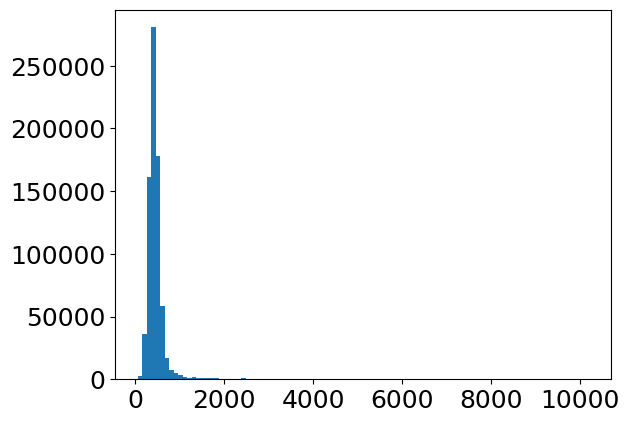

In [7]:
import matplotlib.pyplot as plt
plt.rcParams["font.size"] = 18

plt.hist(df_ch_mol["mw"], bins=100)
plt.show()

In [8]:
df_ch_mol[df_ch_mol["mw"] > 1000]

,smiles,mw
3297,CCCC[C@H](NC(=O)[C@H](Cc1ccc(OS(=O)(=O)O)cc1)N...,1138.504520
3311,CCCC[C@H](NC(=O)[C@H](Cc1ccc(OS(=O)(=O)O)cc1)N...,1048.457570
3312,CCCC[C@H](NC(=O)[C@H](Cc1ccc(OS(=O)(=O)O)cc1)N...,1062.473220
3317,CCCC[C@H](NC(=O)[C@H](Cc1ccc(OS(=O)(=O)O)cc1)N...,1124.488870
3326,CCCC[C@H](NC(=O)[C@H](Cc1ccc(OS(=O)(=O)O)cc1)N...,1138.504520
...,...,...
1553853,COc1c(C)c(OCc2cccc(COc3c(C)c(C)c(C(=O)Oc4c(C)c...,1055.451464
1553855,COc1c(C)c(OC(=O)c2c(C)c(C)c(OC(=O)c3c(C)c(C(=O...,1022.393615
1553856,COc1c(C)c(OC(=O)c2c(C)c(C)c(OC(=O)c3c(C)c(C(=O...,1170.467174
1553884,CO[C@H]1[C@@H]2O[C@H]3O[C@H](COCc4cn(CCCCCCN[C...,3900.887847


In [9]:
df_ch_mol[df_ch_mol["mw"] > 2000]

,smiles,mw
3648,CC[C@H](C)[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@H]...,5338.479123
3649,CC[C@H](C)[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@H]...,5323.468224
3650,CC[C@H](C)[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@H]...,5436.392359
3651,CC[C@H](C)[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@H]...,5421.381460
3652,CCCCCCCCCCCCCCCC(=O)NCCCCCCNC(=O)C1CCCCNC(=O)C...,6122.988986
...,...,...
1553424,CC[C@H](C)[C@@H](NC(=O)[C@@H](NC(=O)[C@H](CC(C...,2838.427086
1553425,CC[C@H](C)[C@H](NC(=O)[C@@H](NC(=O)[C@H](CC(C)...,2650.347379
1553426,CC[C@H](C)[C@H](NC(=O)[C@H](CC(=O)O)NC(=O)[C@@...,4476.364296
1553427,CC[C@H](C)[C@H](NC(=O)[C@@H](NC(=O)[C@H](CC(C)...,2838.427086


In [10]:
df_ch_mol[df_ch_mol["mw"] > 5000].shape

(52, 2)

In [11]:
len(df_ch_mol)

764727

In [12]:
from transformers import BertTokenizer
import regex as re

PATTERN = "(\[[^\]]+]|Br?|Cl?|N|O|S|P|F|I|b|c|n|o|s|p|\(|\)|\.|=|#|-|\+|\\\\|\/|:|~|@|\?|>|\*|\$|\%[0-9]{2}|[0-9])"


class MolTranBertTokenizer(BertTokenizer):
    def __init__(self, vocab_file: str = '',
                 do_lower_case=False,
                 unk_token='<pad>',
                 sep_token='<eos>',
                 pad_token='<pad>',
                 cls_token='<bos>',
                 mask_token='<mask>',
                 **kwargs):
        super().__init__(vocab_file,
                         unk_token=unk_token,
                         sep_token=sep_token,
                         pad_token=pad_token,
                         cls_token=cls_token,
                         mask_token=mask_token,
                         **kwargs)

        self.regex_tokenizer = re.compile(PATTERN)
        self.wordpiece_tokenizer = None
        self.basic_tokenizer = None

    def _tokenize(self, text):
        split_tokens = self.regex_tokenizer.findall(text)
        return split_tokens

    def convert_tokens_to_string(self, tokens):
        out_string = "".join(tokens).strip()
        return out_string


In [13]:
smiles = df_ch_mol[df_ch_mol["mw"]==1000]["smiles"].values
smi_tokenizer = MolTranBertTokenizer('bert_vocab.txt')
smi_tokens = smi_tokenizer.batch_encode_plus(smiles[-100:], padding=True, add_special_tokens=True)

ValueError: You should supply an encoding or a list of encodings to this method that includes input_ids, but you provided []

In [14]:
def calculate_token_length(smiles):
    return len(smi_tokenizer.tokenize(smiles))

In [15]:
df_ch_mol["smi_token_length"] = df_ch_mol["smiles"].apply(calculate_token_length)

In [16]:
df_ch_mol["smi_token_length"].describe()

count    764727.000000
mean         55.523251
std          35.577902
min           4.000000
25%          41.000000
50%          50.000000
75%          61.000000
max        1250.000000
Name: smi_token_length, dtype: float64

In [17]:
df_ch_mol[df_ch_mol["smi_token_length"] <= 202].describe()

,mw,smi_token_length
count,756994.000000,756994.000000
mean,441.730344,52.715817
std,153.865985,19.487843
min,54.010565,4.000000
25%,353.148789,41.000000
50%,422.247618,50.000000
75%,498.147011,60.000000
max,2184.912014,202.000000


<Axes: >

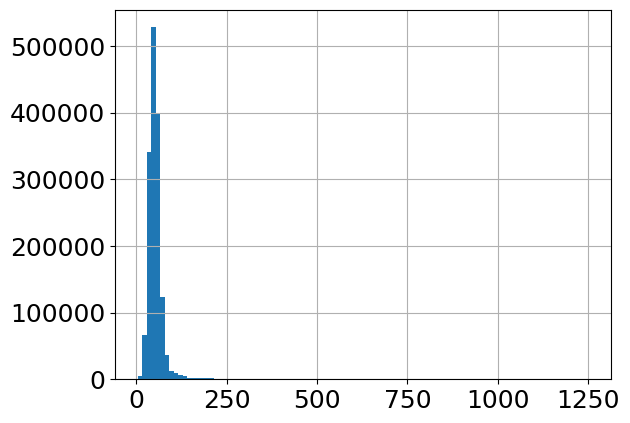

In [18]:
df_ch["smi_token_size"] = df_ch["smiles"].apply(calculate_token_length)
df_ch["smi_token_size"].hist(bins=100)

In [19]:
df_ch_v4 = df_ch[df_ch["smi_token_size"] <= 202]

In [20]:
df_ch_v4.to_csv("chembl_34_activity_classification_v4.csv", index=False)

In [21]:
df_all_only_label_t_1u = df_ch_v4.drop(columns=['t_100n', 't_10u'], axis=1)
df_all_only_label_t_1u.dropna(subset=["t_1u"], inplace=True)

df_all_only_label_t_10u = df_ch_v4.drop(columns=['t_100n', 't_1u'], axis=1)
df_all_only_label_t_10u.dropna(subset=["t_10u"], inplace=True)

df_all_only_label_t_100n = df_ch_v4.drop(columns=['t_1u', 't_10u'], axis=1)
df_all_only_label_t_100n.dropna(subset=["t_100n"], inplace=True)

df_all_only_label_t_1u.to_csv("chembl_34_activity_classification_t_1u_v4.csv", index=False)
df_all_only_label_t_10u.to_csv("chembl_34_activity_classification_t_10u_v4.csv", index=False)
df_all_only_label_t_100n.to_csv("chembl_34_activity_classification_t_100n_v4.csv", index=False)
df_ch_v4.to_csv("chembl_34_activity_classification_v4.csv", index=False)

In [22]:
len(df_ch_v4)

1543449

In [23]:
df_all_only_label_t_1u["t_1u"].value_counts()

t_1u
1.0    787416
0.0    604656
Name: count, dtype: int64

In [2]:
# v4にv2のtoken > 202を追加
import pandas as pd

df_ch_v2 = pd.read_csv("chembl_34_activity_classification_v2.csv")
df_ch_v4 = pd.read_csv("chembl_34_activity_classification_v4.csv")

/tmp/ipykernel_2620133/3430930434.py:4: DtypeWarning: Columns (15,18) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ch_v2 = pd.read_csv("chembl_34_activity_classification_v2.csv")
/tmp/ipykernel_2620133/3430930434.py:5: DtypeWarning: Columns (15,18) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ch_v4 = pd.read_csv("chembl_34_activity_classification_v4.csv")


NameError: name 'calculate_token_length' is not defined

In [3]:
from transformers import BertTokenizer
import regex as re

PATTERN = "(\[[^\]]+]|Br?|Cl?|N|O|S|P|F|I|b|c|n|o|s|p|\(|\)|\.|=|#|-|\+|\\\\|\/|:|~|@|\?|>|\*|\$|\%[0-9]{2}|[0-9])"


class MolTranBertTokenizer(BertTokenizer):
    def __init__(self, vocab_file: str = '',
                 do_lower_case=False,
                 unk_token='<pad>',
                 sep_token='<eos>',
                 pad_token='<pad>',
                 cls_token='<bos>',
                 mask_token='<mask>',
                 **kwargs):
        super().__init__(vocab_file,
                         unk_token=unk_token,
                         sep_token=sep_token,
                         pad_token=pad_token,
                         cls_token=cls_token,
                         mask_token=mask_token,
                         **kwargs)

        self.regex_tokenizer = re.compile(PATTERN)
        self.wordpiece_tokenizer = None
        self.basic_tokenizer = None

    def _tokenize(self, text):
        split_tokens = self.regex_tokenizer.findall(text)
        return split_tokens

    def convert_tokens_to_string(self, tokens):
        out_string = "".join(tokens).strip()
        return out_string


In [4]:
def calculate_token_length(smiles):
    return len(smi_tokenizer.tokenize(smiles))

In [6]:
smi_tokenizer = MolTranBertTokenizer('bert_vocab.txt')
df_ch_v2["smi_token_size"] = df_ch_v2["smiles"].apply(calculate_token_length)

In [8]:
df_ch_v2_token_gt_202 = df_ch_v2[df_ch_v2["smi_token_size"] > 202]
df_ch_v2_token_gt_202

,activity_id,assay_id,target_chembl_id,target_name,target_organism,target_accession,target_sequence,compound_chembl_id,smiles,protein_class_desc,...,Protein families,3D,superfamily,family,subfamily,description,compound_id,protein_id,cp_id,smi_token_size
3648,22772162,2049941,CHEMBL298,Cholecystokinin B receptor,Homo sapiens,P32239,MELLKLNRSVQGTGPGPGASLCRPGAPLLNSSSVGNLSCEPPRIRG...,CHEMBL4783736,CC[C@H](C)[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@H]...,membrane receptor 7tm1 peptide short peptid...,...,G-protein coupled receptor 1 family,Electron microscopy (4); NMR spectroscopy (1),NaN,G-protein coupled receptor 1 family,NaN,NaN,4033,5,4033_5,671
3649,22772163,2049941,CHEMBL298,Cholecystokinin B receptor,Homo sapiens,P32239,MELLKLNRSVQGTGPGPGASLCRPGAPLLNSSSVGNLSCEPPRIRG...,CHEMBL4799182,CC[C@H](C)[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@H]...,membrane receptor 7tm1 peptide short peptid...,...,G-protein coupled receptor 1 family,Electron microscopy (4); NMR spectroscopy (1),NaN,G-protein coupled receptor 1 family,NaN,NaN,4034,5,4034_5,672
3650,22772164,2049941,CHEMBL298,Cholecystokinin B receptor,Homo sapiens,P32239,MELLKLNRSVQGTGPGPGASLCRPGAPLLNSSSVGNLSCEPPRIRG...,CHEMBL4780789,CC[C@H](C)[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@H]...,membrane receptor 7tm1 peptide short peptid...,...,G-protein coupled receptor 1 family,Electron microscopy (4); NMR spectroscopy (1),NaN,G-protein coupled receptor 1 family,NaN,NaN,4035,5,4035_5,679
3651,22772165,2049941,CHEMBL298,Cholecystokinin B receptor,Homo sapiens,P32239,MELLKLNRSVQGTGPGPGASLCRPGAPLLNSSSVGNLSCEPPRIRG...,CHEMBL4784851,CC[C@H](C)[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@H]...,membrane receptor 7tm1 peptide short peptid...,...,G-protein coupled receptor 1 family,Electron microscopy (4); NMR spectroscopy (1),NaN,G-protein coupled receptor 1 family,NaN,NaN,4036,5,4036_5,680
3652,22772166,2049941,CHEMBL298,Cholecystokinin B receptor,Homo sapiens,P32239,MELLKLNRSVQGTGPGPGASLCRPGAPLLNSSSVGNLSCEPPRIRG...,CHEMBL4788440,CCCCCCCCCCCCCCCC(=O)NCCCCCCNC(=O)C1CCCCNC(=O)C...,membrane receptor 7tm1 peptide short peptid...,...,G-protein coupled receptor 1 family,Electron microscopy (4); NMR spectroscopy (1),NaN,G-protein coupled receptor 1 family,NaN,NaN,4037,5,4037_5,757
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1553426,19347338,1917542,CHEMBL3713062,Tissue factor pathway inhibitor,Homo sapiens,P10646,MIYTMKKVHALWASVCLLLNLAPAPLNADSEEDEEHTIITDTELPP...,CHEMBL4461743,CC[C@H](C)[C@H](NC(=O)[C@H](CC(=O)O)NC(=O)[C@@...,unclassified,...,NaN,Electron microscopy (1); NMR spectroscopy (2);...,NaN,NaN,NaN,Inhibition of C-terminus 10x-His-taged human T...,761312,764,761312_764,544
1553427,19347395,1917542,CHEMBL3713062,Tissue factor pathway inhibitor,Homo sapiens,P10646,MIYTMKKVHALWASVCLLLNLAPAPLNADSEEDEEHTIITDTELPP...,CHEMBL4440277,CC[C@H](C)[C@H](NC(=O)[C@@H](NC(=O)[C@H](CC(C)...,unclassified,...,NaN,Electron microscopy (1); NMR spectroscopy (2);...,NaN,NaN,NaN,Inhibition of C-terminus 10x-His-taged human T...,761313,764,761313_764,341
1553702,25010492,2276382,CHEMBL2929,Subtilisin/kexin type 9,Homo sapiens,Q8NBP7,MGTVSSRRSWWPLPLLLLLLLLLGPAGARAQEDEDGDYEELVLALR...,CHEMBL5094892,CC(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@@H](Cc1ccccc...,enzyme protease serine sb s8a,...,Peptidase S8 family,Electron microscopy (3); X-ray crystallography...,NaN,Peptidase S8 family,NaN,Inhibition of PCSK9 in human HepG2 cells asses...,762419,964,762419_964,213
1553703,25010493,2276382,CHEMBL2929,Subtilisin/kexin type 9,Homo sapiens,Q8NBP7,MGTVSSRRSWWPLPLLLLLLLLLGPAGARAQEDEDGDYEELVLALR...,CHEMBL5285300,CC(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@@H](Cc1ccccc...,enzyme protease serine sb s8a,...,Peptidase S8 family,Electron microscopy (3); X-ray crystallography...,NaN,Peptidase S8 family,NaN,Inhibition of PCSK9 in human HepG2 cells asses...,762420,964,762420_964,227


In [9]:
df_ch_v5 = pd.concat([df_ch_v4, df_ch_v2_token_gt_202], axis=0).reset_index(drop=True)

In [10]:
len(df_ch_v5)

1554237

In [12]:
df_v2_token_gt_202_t_1u = df_ch_v2_token_gt_202.drop(columns=['t_100n', 't_10u'], axis=1)
df_v2_token_gt_202_t_1u.dropna(subset=["t_1u"], inplace=True)

df_v5_t_1u = df_ch_v5.drop(columns=['t_100n', 't_10u'], axis=1)
df_v5_t_1u.dropna(subset=["t_1u"], inplace=True)

In [13]:
df_v5_t_1u.to_csv("chembl_34_activity_classification_t_1u_v5.csv", index=False)
df_v2_token_gt_202_t_1u.to_csv("chembl_34_activity_classification_t_1u_v2_token_gt_202.csv", index=False)